# Fig. S3: spectroscopy of a rhombohedral graphite nanoribbon


    Panels **a, b**: dI/dV line spectrum 747 across a thin (+⁵) ribbon bounded by regions of
    unidentified stacking (stf1, stf2) and a (+⁴−) region, and its derivative along the bias.
    Panels **c, d**: tight-binding LDOS along a line across a (+⁵) ribbon (system 3, the shorter
    confined ABC ribbon of the TB line spectra) and its energy derivative.

    Data: `MK_ABC_FLG_25_9K_2023_11_04_05_31_09_747.sm4`, `x_3_MARCI.txt`, `ldos_3_MARCI.txt.gz`, `TB_LS_E.txt`.
    System 2 (`x_2_MARCI.txt`, `ldos_2_MARCI.txt.gz`) is the longer ribbon and can be plotted the same way.


Paper: Kandrai, K. *et al.* One-way electron mirrors from single-layer stacking shifts in rhombohedral graphite. Preprint at https://arxiv.org/abs/2610.20905 (2026).

In [1]:
import os
import sys
import requests
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import rhkpy
import xarray as xr
from scipy.ndimage import gaussian_filter

In [2]:
print('python', sys.version.split()[0])
print('numpy', np.__version__)
print('matplotlib', matplotlib.__version__)
print('rhkpy', rhkpy.__version__)
print('xarray', xr.__version__)

python 3.13.5
numpy 2.1.3
matplotlib 3.10.0
rhkpy 1.3.9
xarray 2025.4.0


In [3]:
# figure style of the paper: scienceplots if it is installed, plain matplotlib otherwise
try:
    import scienceplots  # noqa: F401
    plt.style.use(['science', 'no-latex', 'nature', 'std-colors'])
except ImportError:
    pass
matplotlib.rcParams['pdf.fonttype'] = 42   # editable text in Inkscape / Illustrator
matplotlib.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['figure.dpi'] = 110

In [4]:
# Data files are downloaded from Zenodo into DATA_DIR if they are not there yet.
ZENODO_RECORD = '23419464'   # record number of the data set, https://zenodo.org/records/<ZENODO_RECORD>
DATA_DIR = 'data'

FILES = ['MK_ABC_FLG_25_9K_2023_11_04_05_31_09_747.sm4', 'TB_LS_E.txt', 'x_3_MARCI.txt', 'ldos_3_MARCI.txt.gz']


def get_data(filename, record=ZENODO_RECORD, data_dir=DATA_DIR):
    """Return the local path of a data file, downloading it from Zenodo first if needed."""
    path = os.path.join(data_dir, filename)
    if os.path.exists(path):
        return path
    os.makedirs(data_dir, exist_ok=True)
    url = f'https://zenodo.org/records/{record}/files/{requests.utils.quote(filename)}?download=1'
    print(f'Downloading {filename} ...')
    with requests.get(url, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(path, 'wb') as fh:
            for chunk in r.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
    print(f'  saved to {path}')
    return path


for f in FILES:
    get_data(f)

In [5]:
def extent_of(da, xdim, ydim):
    """imshow extent (outer pixel edges) of an xarray DataArray with uniform coordinates."""
    x, y = da[xdim].values, da[ydim].values
    dx = (x[-1] - x[0]) / (x.size - 1)
    dy = (y[-1] - y[0]) / (y.size - 1)
    return [x[0] - dx / 2, x[-1] + dx / 2, y[0] - dy / 2, y[-1] + dy / 2]


def extent_xy(x, y):
    """imshow extent (outer pixel edges) for two uniform coordinate arrays."""
    dx = (x[-1] - x[0]) / (x.size - 1)
    dy = (y[-1] - y[0]) / (y.size - 1)
    return [x[0] - dx / 2, x[-1] + dx / 2, y[0] - dy / 2, y[-1] + dy / 2]

## Panels a, b: line spectrum 747

Mean over the repetitions and the sweep directions, normalization to the mean of the first and last
current values, crop to 0-70 nm and −0.35 to +0.2 V, 7 × 7 running mean, derivative along the bias,
and a final 3 × 3 running mean of the derivative, as in the figure.

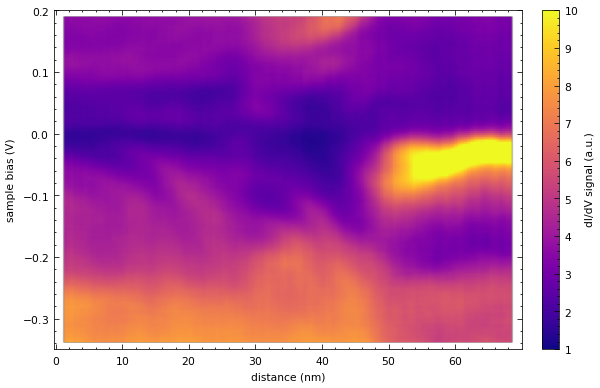

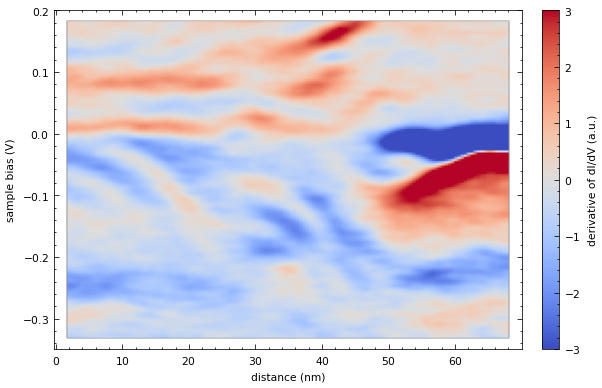

In [6]:
line_spec_747 = rhkpy.rhkdata(get_data('MK_ABC_FLG_25_9K_2023_11_04_05_31_09_747.sm4'))
ls_mean = line_spec_747.spectra.mean(dim=['repetitions', 'biasscandir'])
current_first = -ls_mean.current[0, :].data
current_last = ls_mean.current[-1, :].data
ls_norm = 2 * ls_mean / (current_first + current_last)

ls_crop = ls_norm.sel(dist=slice(0, 70), bias=slice(-0.35, 0.2))
ls_crop_mean = ls_crop.rolling(dist=7, bias=7, center=True).mean()
lia = ls_crop_mean.lia
grad = lia.copy(data=np.gradient(lia.data, axis=lia.dims.index('bias')))
grad_mean = grad.rolling(dist=3, bias=3, center=True).mean()


def plot_lia(da, cbar_label, cmap, vmin, vmax, figsize=(6, 4), title=None):
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(da.transpose('bias', 'dist').values, cmap=cmap, aspect='auto', origin='lower',
                   extent=extent_of(da, 'dist', 'bias'), vmin=vmin, vmax=vmax)
    ax.set_xlabel('distance (nm)'); ax.set_ylabel('sample bias (V)')
    if title:
        ax.set_title(title, fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label(cbar_label)
    return fig, ax


plot_lia(lia * 1000, 'dI/dV signal (a.u.)', 'plasma', 1, 10)                       # panel a
plt.show()
plot_lia(grad_mean * 10000, 'derivative of dI/dV (a.u.)', 'coolwarm', -3, 3)       # panel b
plt.show()

## Panels c, d: tight-binding LDOS of the (+⁵) ribbon

The LDOS is smoothed with a Gaussian of 4 energy pixels along the energy axis; the derivative is
taken along the energy axis. The full length of the calculated section is shown.

(1000, 664) section length 81.549 nm


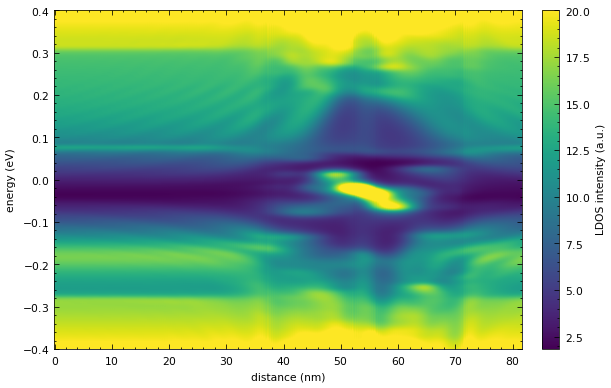

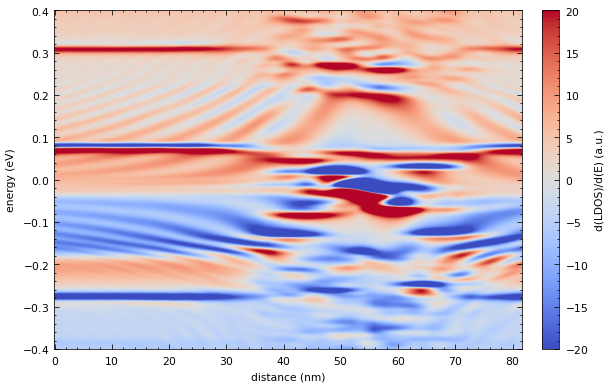

In [7]:
x = np.loadtxt(get_data('x_3_MARCI.txt'))
ldos = np.loadtxt(get_data('ldos_3_MARCI.txt.gz'))
E_tb = np.loadtxt(get_data('TB_LS_E.txt'))
print(ldos.shape, 'section length', (x.max() - x.min()) / 10, 'nm')

Elim = 0.4
SIGMA = (4, 0)
E_mask = (E_tb >= -Elim) & (E_tb <= Elim)
dist_nm = (x - x[0]) / 10
ldos_s = gaussian_filter(ldos, sigma=SIGMA)[E_mask, :]
grad_s = gaussian_filter(np.gradient(ldos, E_tb, axis=0) * 100, sigma=SIGMA)[E_mask, :]
extent_tb = extent_xy(dist_nm, E_tb[E_mask])

for arr, cmap, vmin, vmax, label in ((ldos_s * 1000, 'viridis', None, 20, 'LDOS intensity (a.u.)'),
                                     (grad_s, 'coolwarm', -20, 20, 'd(LDOS)/d(E) (a.u.)')):
    fig, ax = plt.subplots(figsize=(6, 4))
    im = ax.imshow(arr, cmap=cmap, aspect='auto', origin='lower', extent=extent_tb, vmin=vmin, vmax=vmax)
    ax.set_xlabel('distance (nm)'); ax.set_ylabel('energy (eV)')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label(label)
    plt.show()